# Generate molecular spectra

A single bundled model can generate a wavelength axis and flux in two lines. `logN=18` means a column density of $10^{18}\,\mathrm{cm}^{-2}$; `A=1` means an emitting area of 1 au². The checkpoint flux convention is a source at 140 pc.

```python
from diskmelts import synthesize_spectrum
wave, flux = synthesize_spectrum('HCN', T=300, logN=18, A=1)
```

Change the molecule, parameters, `sigma`, `distance_pc`, or optional `wavelength` grid to make your own spectrum. The cells below load models once to draw many species efficiently. They show individual model spectra, **not** a chemically realistic mixture: all species have the same illustrative column density and area. Water is excluded.

In [1]:
from diskmelts import synthesize_spectrum
wave_hcn, flux_hcn = synthesize_spectrum('HCN', T=300, logN=18, A=1)
print(f'HCN: {len(wave_hcn)} wavelengths; peak = {flux_hcn.max():.4g} Jy')

  [HCN] loaded from .../site-packages/diskmelts/models/Trained_model/sigma0/HCN_single_v2/net_HCN_forward.pt
  Loaded HCN from .../site-packages/diskmelts/models/Trained_model/sigma0/HCN_single_v2/net_HCN_forward.pt
HCN: 2275 wavelengths; peak = 0.04554 Jy


## Shared settings

The default here is `sigma=2`; set `GRID_SIGMA = 0` for the sigma=0 checkpoints, which cover every species shown. `synthesize_spectrum` requires DiskMELTS 2.2.1 or newer. The common wavelength grid is in µm; model fluxes are in Jy.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from diskmelts import generate_spectrum, load_fitting_models

T, LOGN, A, GRID_SIGMA = 300, 18, 1.0, 2
MAIN = ('CH4', 'C2H4', 'C2H6', 'C2H2', 'HCN', 'CO2',
        'C6H6', 'HC3N', 'C4H2', 'CH3', 'C3H4', 'OH')
RARE = ('13C12CH2', 'C2HD', '13CO2', 'CO17O', 'CO18O')
MOLECULES = MAIN + RARE
wave = np.linspace(5.0, 26.0, 4201)
models = load_fitting_models(MOLECULES, sigma=GRID_SIGMA)
spectra = {mol: generate_spectrum(T, LOGN, A, models[mol], obs_wav=wave)
           for mol in MOLECULES}
assert all(np.isfinite(flux).all() and flux.max() > 0 for flux in spectra.values())

root = Path.cwd()
if not (root / 'docs' / 'source').is_dir():
    root = root.parent
figure_dir = root / 'docs' / 'source' / '_static' / 'examples'
save_docs_figures = figure_dir.is_dir()

  [CH4] loaded from .../site-packages/diskmelts/models/Trained_model/sigma2/CH4_single_v2/net_CH4_forward.pt
  Loaded CH4 from .../site-packages/diskmelts/models/Trained_model/sigma2/CH4_single_v2/net_CH4_forward.pt
  [C2H4] loaded from .../site-packages/diskmelts/models/Trained_model/sigma2/C2H4_single_v2/net_C2H4_forward.pt
  Loaded C2H4 from .../site-packages/diskmelts/models/Trained_model/sigma2/C2H4_single_v2/net_C2H4_forward.pt
  [C2H6] loaded from .../site-packages/diskmelts/models/Trained_model/sigma2/C2H6_single_v2/net_C2H6_forward.pt
  Loaded C2H6 from .../site-packages/diskmelts/models/Trained_model/sigma2/C2H6_single_v2/net_C2H6_forward.pt
  [C2H2] loaded from .../site-packages/diskmelts/models/Trained_model/sigma2/C2H2_wavelength_bank_v2/net_C2H2_w6to9.pt
  [C2H2] loaded from .../site-packages/diskmelts/models/Trained_model/sigma2/C2H2_wavelength_bank_v2/net_C2H2_w11p5to17.pt
  Loaded C2H2 model bank from .../site-packages/diskmelts/models/Trained_model/sigma2/C2H2_wavelen

## Main species, 5–26 µm

These are the main molecules requested, plus C3H4 and OH, which are also bundled. Every line is a separate 300 K, logN=18, A=1 au² model at 140 pc. To compare where each molecule emits, each curve is divided by its own peak flux within 5–26 µm and shown on a linear axis. Curve heights therefore do not compare absolute brightness between molecules.

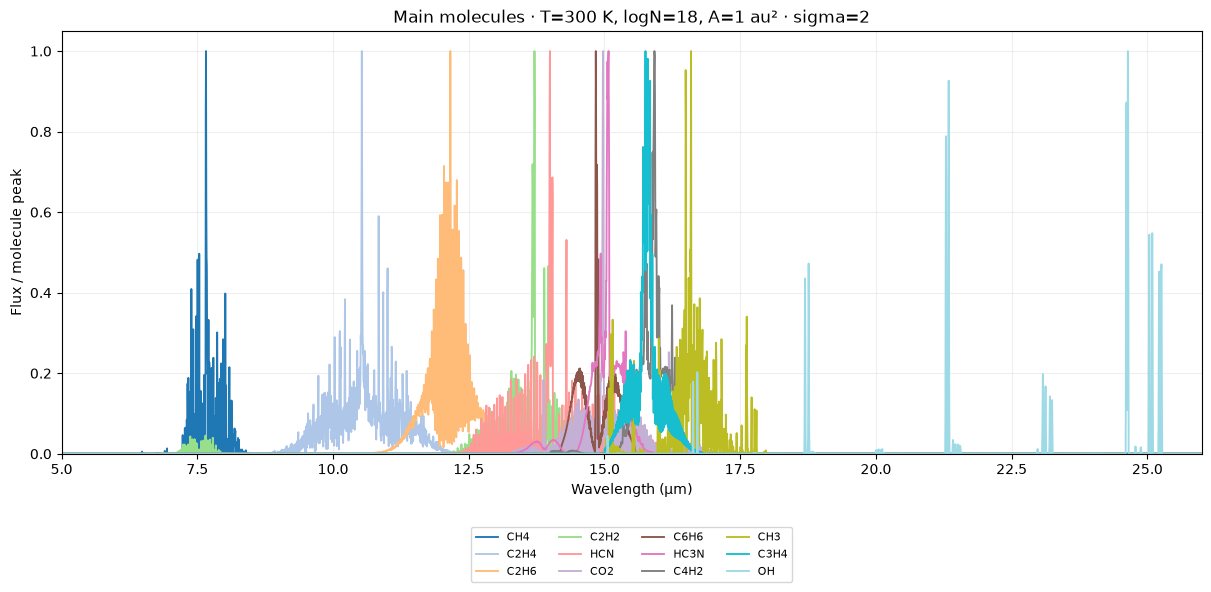

In [3]:
fig, ax = plt.subplots(figsize=(12, 5.8), constrained_layout=True)
colors = plt.cm.tab20(np.linspace(0, 1, len(MAIN)))
for mol, color in zip(MAIN, colors):
    flux = spectra[mol]
    ax.plot(wave, flux / flux.max(), label=mol,
            color=color, linewidth=1.35)
ax.set(xlim=(5, 26), ylim=(0, 1.05), xlabel='Wavelength (µm)',
       ylabel='Flux / molecule peak', title=f'Main molecules · T={T} K, logN={LOGN}, A={A:g} au² · sigma={GRID_SIGMA}')
ax.grid(alpha=0.2)
ax.legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16))
if save_docs_figures:
    fig.savefig(figure_dir / 'synthetic_main_molecules.png', dpi=180, bbox_inches='tight')
plt.show()

## Main molecules and rarer isotopologues, 13–18 µm

The zoom compares C2H2, HCN and CO2 with available rarer isotopologues. The C2H2 family includes 13C12CH2 and C2HD; the CO2 family includes 13CO2, CO17O and CO18O. No rarer HCN checkpoint is bundled. Each curve is divided by its own peak flux within 13–18 µm and shown on a linear axis to reveal its main emitting wavelengths. Equal logN across these lines is only for comparing model shapes, not realistic isotope abundances.

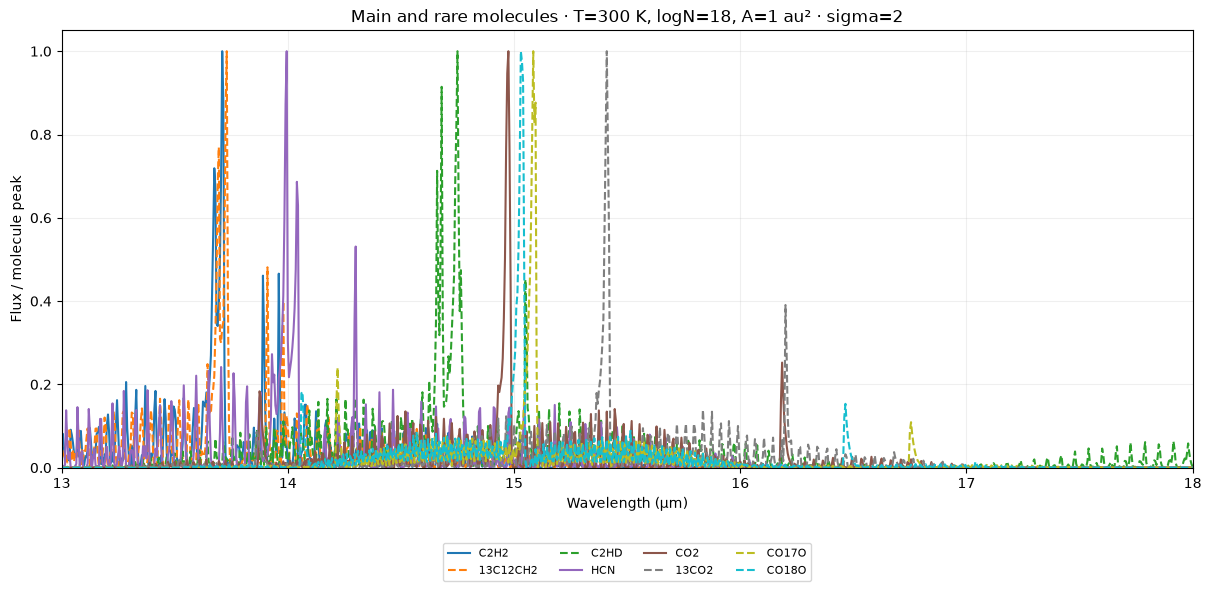

In [4]:
zoom = ('C2H2', '13C12CH2', 'C2HD', 'HCN',
        'CO2', '13CO2', 'CO17O', 'CO18O')
zoom_mask = (wave >= 13) & (wave <= 18)
fig, ax = plt.subplots(figsize=(12, 5.8), constrained_layout=True)
colors = plt.cm.tab10(np.linspace(0, 1, len(zoom)))
for mol, color in zip(zoom, colors):
    flux = spectra[mol]
    ax.plot(wave[zoom_mask], flux[zoom_mask] / flux[zoom_mask].max(), label=mol,
            color=color, linestyle='--' if mol in RARE else '-',
            linewidth=1.5)
ax.set(xlim=(13, 18), ylim=(0, 1.05), xlabel='Wavelength (µm)',
       ylabel='Flux / molecule peak', title=f'Main and rare molecules · T={T} K, logN={LOGN}, A={A:g} au² · sigma={GRID_SIGMA}')
ax.grid(alpha=0.2)
ax.legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16))
if save_docs_figures:
    fig.savefig(figure_dir / 'synthetic_isotopologues_13to18.png', dpi=180, bbox_inches='tight')
plt.show()